In [36]:
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gensim.downloader as api
from gensim.models import Word2Vec, FastText
from gensim.models.fasttext import FastTextKeyedVectors

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.decomposition import PCA

import sys
sys.path.append("..")  # project root, so `lib` can be imported
from lib.text_processing import text_preprocessing

In [37]:
path = "../data/processed"

df_train, df_val, df_test = (pd.read_csv(f"{path}/{s}.csv") for s in ['train', 'val', "test"])

In [38]:
for d in (df_train, df_val, df_test):
    d["emb_text"] = d['text'].apply(text_preprocessing, lemmatize=False)

In [39]:
y_train, y_val, y_test = df_train.label.values, df_val.label.values, df_test.label.values

In [40]:
token = lambda t: t.str.split()
model = {
    "w2v_pretrained":  api.load("word2vec-google-news-300"),
    "glove_twitter":   api.load("glove-twitter-200"),
    "fasttext_pre":    api.load("fasttext-wiki-news-subwords-300"),
    "w2v_own":  Word2Vec(token(df_train.emb_text), vector_size=100, sg=1, min_count=1, epochs=30, seed=42).wv,
    "ft_own":   FastText(token(df_train.emb_text), vector_size=100, sg=1, min_count=1, epochs=30, seed=42).wv,
}

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


In [41]:
def find_word(kv, word):
    for candidate in (word, word.capitalize(), word.upper()):
        if candidate in kv.key_to_index:
            return candidate
    return None


def word_vector(kv, word):
    key = find_word(kv, word)
    if key is not None:
        return kv[key]
    if isinstance(kv, FastTextKeyedVectors):
        return kv[word]
    return None

In [42]:
probe_words = ["angry", "happy", "sad", "hopeful"]

for name, kv in model.items():
    print(name)
    for w in probe_words:
        key = find_word(kv, w)
        if key is None:
            print(f"  {w} -> OOV")
        else:
            print(f"  {w} ->", [x for x, _ in kv.most_similar(key, topn=5)])

w2v_pretrained
  angry -> ['irate', 'enraged', 'indignant', 'incensed', 'annoyed']
  happy -> ['glad', 'pleased', 'ecstatic', 'overjoyed', 'thrilled']
  sad -> ['saddening', 'Sad', 'saddened', 'heartbreaking', 'disheartening']
  hopeful -> ['optimistic', 'cautiously_optimistic', 'confident', 'guardedly_optimistic', 'hoping']
glove_twitter
  angry -> ['birds', 'mad', 'annoyed', 'upset', 'frustrated']
  happy -> ['birthday', 'day', 'bday', 'wish', 'merry']
  sad -> ['depressing', 'really', 'depressed', 'sick', 'feel']
  hopeful -> ['optimistic', 'hoping', 'doubtful', 'determined', 'upbeat']
fasttext_pre
  angry -> ['enraged', 'irate', 'furious', 'indignant', 'frustrated']
  happy -> ['happpy', 'happy-', 'happy-happy', 'unhappy', 'happier']
  sad -> ['sorrowful', 'saddening', 'happy-sad', 'regretful', 'tragic']
  hopeful -> ['optimistic', 'hopefull', 'ever-hopeful', 'hope-filled', 'hope']
w2v_own
  angry -> ['err', 'infuriating', 'beard', 'mufc', 'rides']
  happy -> ['happyy', 'exterior',

In [43]:
pairs = [("happy", "joyful"), ("happy", "sad"), ("angry", "furious"), ("angry", "banana")]

sim_rows = {}
for w1, w2 in pairs:
    sim_rows[f"{w1} / {w2}"] = {}
    for name, kv in model.items():
        k1, k2 = find_word(kv, w1), find_word(kv, w2)
        sim_rows[f"{w1} / {w2}"][name] = round(float(kv.similarity(k1, k2)), 3) if k1 and k2 else None
pd.DataFrame(sim_rows).T

,w2v_pretrained,glove_twitter,fasttext_pre,w2v_own,ft_own
happy / joyful,0.424,0.352,0.713,0.532,0.656
happy / sad,0.535,0.579,0.690,0.252,0.376
angry / furious,0.670,0.368,0.778,0.407,0.527
angry / banana,0.105,0.262,0.268,0.376,0.534


In [44]:
def coverage(texts, kv):
    tokens = [w for t in texts for w in t.split()]
    return sum(find_word(kv, w) is not None for w in tokens) / len(tokens)

In [45]:
oov_table = pd.DataFrame({
    name: {"train": coverage(df_train.emb_text, kv),
           "val":   coverage(df_val.emb_text, kv),
           "test":  coverage(df_test.emb_text, kv)}
    for name, kv in model.items()}).T.round(3)
oov_table

,train,val,test
w2v_pretrained,0.960,0.965,0.955
glove_twitter,0.970,0.974,0.967
fasttext_pre,0.963,0.967,0.957
w2v_own,1.000,0.810,0.792
ft_own,1.000,0.810,0.792


In [46]:
word_counts = Counter(tok for t in df_train.emb_text for tok in t.split())

for name in model.keys():
    kv = model[name]
    oov = [w for w in word_counts if find_word(kv, w) is None]
    print(f"{name}: unique OOV words {len(oov)} / {len(word_counts)} ({len(oov) / len(word_counts):.1%})")
    print("   most frequent OOV:", sorted(oov, key=word_counts.get, reverse=True)[:20])

w2v_pretrained: unique OOV words 952 / 7983 (11.9%)
   most frequent OOV: ['gbbo', 'snapchat', 'mhchat', 'charlotteprotest', 'kikme', 'cantsleep', 'peoplelikemebecause', 'lethalweapon', 'nevertrump', 'nawazsharif', 'snapme', 'happyy', 'szn', 'anxietyprobz', 'amwriting', 'nfunny', 'dreamornightmare', 'hoco', 'notfair', 'aflcatsswans']
glove_twitter: unique OOV words 749 / 7983 (9.4%)
   most frequent OOV: ['mhchat', 'charlotteprotest', 'peoplelikemebecause', 'lethalweapon', 'nevertrump', 'nawazsharif', 'snapme', 'hatered', 'anxietyprobz', 'dreamornightmare', 'aflcatsswans', 'terencecrutcher', 'rueful', 'internationaldayofpeace', 'bbfinale', 'extremeworld', 'cumtribute', 'dayfiance', 'xph', 'fellwinters']
fasttext_pre: unique OOV words 915 / 7983 (11.5%)
   most frequent OOV: ['mhchat', 'charlotteprotest', 'kikme', 'cantsleep', 'peoplelikemebecause', 'lethalweapon', 'nevertrump', 'nawazsharif', 'snapme', 'happyy', 'szn', 'anxietyprobz', 'amwriting', 'nfunny', 'dreamornightmare', 'hoco', 

In [47]:
def sentence_vector(tokens, kv):
    vectors = [v for v in (word_vector(kv, tok) for tok in tokens) if v is not None]
    if len(vectors) == 0:
        return np.zeros(kv.vector_size)
    return np.mean(vectors, axis=0)

features = {
    name: tuple(np.vstack([sentence_vector(t.split(), kv) for t in d.emb_text])
                for d in (df_train, df_val, df_test))
    for name, kv in model.items()}

In [48]:
features.keys()

dict_keys(['w2v_pretrained', 'glove_twitter', 'fasttext_pre', 'w2v_own', 'ft_own'])

In [49]:
tfidf = TfidfVectorizer(min_df=2, ngram_range=(1, 2), max_features=2000, norm="l2")
X_train_tfidf = tfidf.fit_transform(df_train["cleaned_text"])
X_val_tfidf = tfidf.transform(df_val["cleaned_text"])
X_test_tfidf = tfidf.transform(df_test["cleaned_text"])

clf_tfidf = LogisticRegression(C=1.0, max_iter=2000, class_weight='balanced', random_state=42)
clf_tfidf.fit(X_train_tfidf, y_train)
pred_tfidf_val, pred_tfidf = clf_tfidf.predict(X_val_tfidf), clf_tfidf.predict(X_test_tfidf)

tfidf_row = {"val_macro_f1": f1_score(y_val, pred_tfidf_val, average="macro"),
             "test_accuracy": accuracy_score(y_test, pred_tfidf),
             "test_macro_f1": f1_score(y_test, pred_tfidf, average="macro")}
print("TF-IDF baseline:", {k: round(v, 3) for k, v in tfidf_row.items()})

TF-IDF baseline: {'val_macro_f1': 0.607, 'test_accuracy': 0.69, 'test_macro_f1': 0.649}


In [50]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

rows = []
for name, (Xtr, Xva, Xte) in features.items():
    clf = LogisticRegression(C=1.0, max_iter=2000, class_weight='balanced', random_state=42)
    clf.fit(Xtr, y_train)
    pv, pt = clf.predict(Xva), clf.predict(Xte)
    
    rows.append({"embedding": name,
                 "val_macro_f1":  f1_score(y_val, pv, average="macro"),
                 "test_accuracy": accuracy_score(y_test, pt),
                 "test_macro_f1": f1_score(y_test, pt, average="macro")})
pd.DataFrame(rows).round(3).sort_values("test_macro_f1", ascending=False)

,embedding,val_macro_f1,test_accuracy,test_macro_f1
0,w2v_pretrained,0.610,0.729,0.684
1,glove_twitter,0.617,0.704,0.663
2,fasttext_pre,0.608,0.688,0.647
4,ft_own,0.530,0.612,0.576
3,w2v_own,0.519,0.606,0.568


In [51]:
from IPython.display import display

emb_results = pd.DataFrame(rows).set_index("embedding")
comparison = pd.concat([pd.DataFrame([tfidf_row], index=["tfidf (baseline)"]), emb_results]).round(3)
display(comparison.sort_values("test_macro_f1", ascending=False))

,val_macro_f1,test_accuracy,test_macro_f1
w2v_pretrained,0.610,0.729,0.684
glove_twitter,0.617,0.704,0.663
tfidf (baseline),0.607,0.690,0.649
fasttext_pre,0.608,0.688,0.647
ft_own,0.530,0.612,0.576
w2v_own,0.519,0.606,0.568


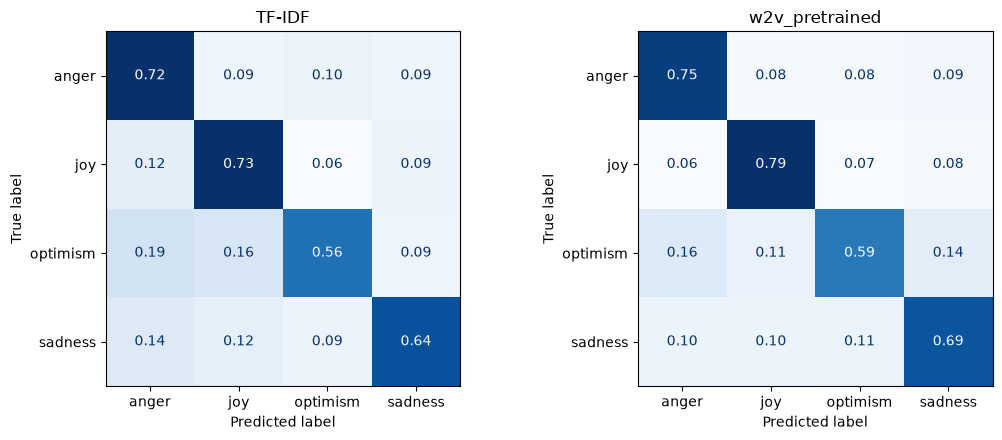

In [52]:
labels = ["anger", "joy", "optimism", "sadness"]
best_emb = emb_results["test_macro_f1"].idxmax()
clf_emb = LogisticRegression(C=1.0, max_iter=2000, class_weight='balanced', random_state=42)
clf_emb.fit(features[best_emb][0], y_train)
pred_emb = clf_emb.predict(features[best_emb][2])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (title, pred) in zip(axes, [("TF-IDF", pred_tfidf), (best_emb, pred_emb)]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=labels, ax=ax, colorbar=False,
                                            cmap="Blues", normalize="true", values_format=".2f")
    ax.set_title(title)
plt.tight_layout()
plt.show()

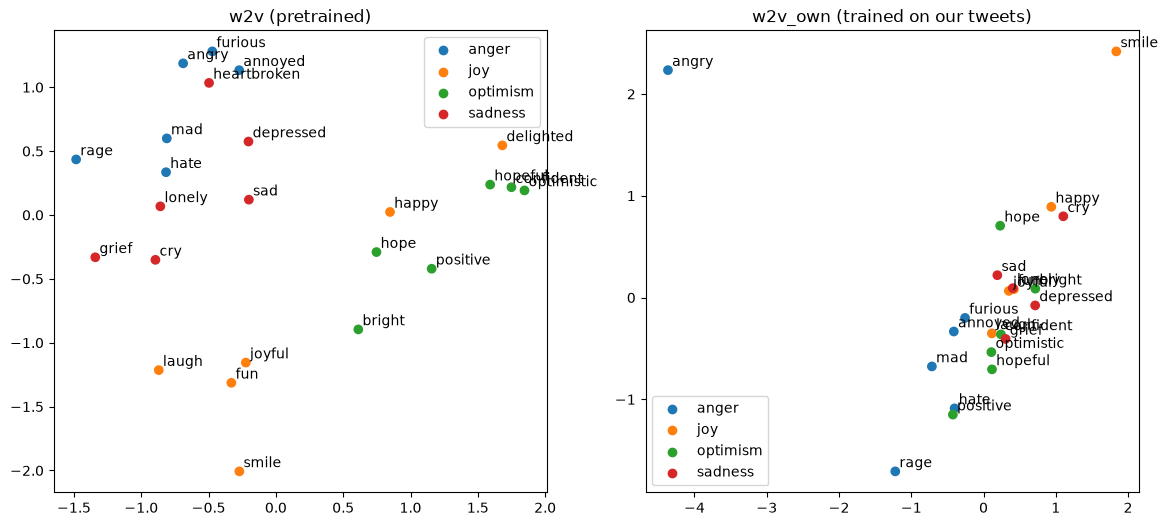

In [53]:
word_groups = {
    "anger":    ["angry", "furious", "mad", "hate", "rage", "annoyed"],
    "joy":      ["happy", "joyful", "delighted", "smile", "laugh", "fun"],
    "optimism": ["hope", "hopeful", "optimistic", "positive", "confident", "bright"],
    "sadness":  ["sad", "cry", "depressed", "lonely", "grief", "heartbroken"],
}


def plot_words(kv, word_groups, ax, title):
    words, colors = [], []
    for i, group_words in enumerate(word_groups.values()):
        for w in group_words:
            key = find_word(kv, w)
            if key is not None:
                words.append(key)
                colors.append(f"C{i}")
    points = PCA(n_components=2).fit_transform(np.array([kv[w] for w in words]))
    ax.scatter(points[:, 0], points[:, 1], c=colors)
    for (x, y), w in zip(points, words):
        ax.annotate(w, (x, y), xytext=(3, 3), textcoords="offset points")
    for i, group in enumerate(word_groups):
        ax.scatter([], [], c=f"C{i}", label=group)
    ax.legend()
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_words(model["w2v_pretrained"], word_groups, axes[0], "w2v (pretrained)")
plot_words(model["w2v_own"], word_groups, axes[1], "w2v_own (trained on our tweets)")
plt.show()

In [54]:
results = pd.DataFrame({
    "Dim": {n: kv.vector_size for n, kv in model.items()},
    "Test coverage %": (oov_table["test"] * 100).round(1),
    "Emb acc": emb_results["test_accuracy"],
    "Emb F1": emb_results["test_macro_f1"],
    "TF-IDF acc": tfidf_row["test_accuracy"],
    "TF-IDF F1": tfidf_row["test_macro_f1"],
}).round(3)
results

,Dim,Test coverage %,Emb acc,Emb F1,TF-IDF acc,TF-IDF F1
w2v_pretrained,300,95.5,0.729,0.684,0.69,0.649
glove_twitter,200,96.7,0.704,0.663,0.69,0.649
fasttext_pre,300,95.7,0.688,0.647,0.69,0.649
w2v_own,100,79.2,0.606,0.568,0.69,0.649
ft_own,100,79.2,0.612,0.576,0.69,0.649


In [61]:
text = "I'm not happy about this shhti"
label_names = {0: "anger", 1: "joy", 2: "optimism", 3: "sadness"}

text = text_preprocessing(text, lemmatize=False)
emb_text = sentence_vector(text.split(), model['w2v_pretrained']).reshape(1, -1)
p = clf_emb.predict_proba(emb_text)

In [66]:
print(label_names[p.argmax()], dict(zip(label_names.values(), p.round(2))))

joy {'anger': array([0.01, 0.54, 0.15, 0.3 ], dtype=float32)}
